In [9]:
from platy_reg.n5_utils import read_volume
import matplotlib.pyplot as plt
from skimage.transform import resize
from pathlib import Path
from skimage.measure import regionprops_table
import pandas as pd
import numpy as np

## Download data from S3

module load rclone

# Download cell segmentation

rclone copy -P -v platybrowser:platybrowser/1.0.1/images/local/sbem-6dpf-1-whole-segmented-cells.n5 ./sbem-6dpf-1-whole-segmented-cells.n5

# Download a random gene
rclone copy -P -v platybrowser:platybrowser/0.6.3/images/local/prospr-6dpf-1-whole-rpc2.n5 ./prospr-6dpf-1-whole-rpc2.n5



Generate commands to download all prospr genes

In [10]:
prospr_xml_dir = Path("/g/kreshuk/buglakova/projects/platy_registration/data/platybrowser-smfish-project/data/1.0.1/images/local")
download_commands = [f"rclone copy -P -v platybrowser:platybrowser/0.6.3/images/local/{p.stem}.n5 /scratch/buglakova/data/prospr/prospr/{p.stem}.n5;\n" for p in prospr_xml_dir.glob("*xml")]
with open("prospr_download_script.sh", "w") as f:
    for command in download_commands:
        f.write(command)

After that manually delete all the non-gene paths and `sh prospr_download_script.sh`

In [11]:
cell_segm = read_volume("/scratch/buglakova/data/prospr/sbem-6dpf-1-whole-segmented-cells.n5", "setup0/timepoint0/s4")

<class 'str'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s4 from /scratch/buglakova/data/prospr/sbem-6dpf-1-whole-segmented-cells.n5
Read volume with shape (714, 810, 860), data type uint64


In [12]:
prospr_image_dir = Path("/scratch/buglakova/data/prospr/prospr")
prospr_image_paths = list(prospr_image_dir.glob("*"))

In [13]:
len(prospr_image_paths)

205

In [14]:
prospr_img = read_volume(prospr_image_paths[0], "setup0/timepoint0/s0")
cell_segm = resize(cell_segm, prospr_img.shape, order=0)


<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-fvri.n5
Read volume with shape (519, 471, 500), data type uint8


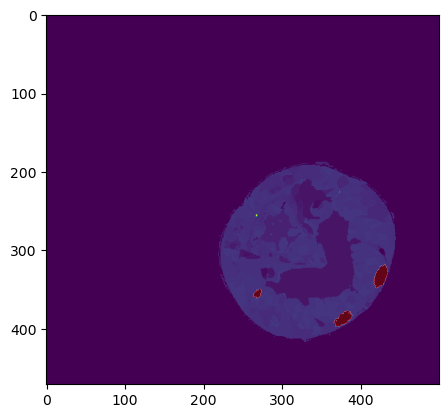

In [15]:
frame = 100
plt.imshow(cell_segm[frame])
plt.imshow(prospr_img[frame], cmap="Reds", alpha=(prospr_img[frame] > 0) * 0.9)

In [16]:
props = regionprops_table(cell_segm[250], intensity_image=prospr_img[250], properties=["label", "intensity_max", "intensity_mean"])

In [17]:
data = pd.DataFrame(props) 

In [18]:
cell_ids = np.unique(cell_segm[250])[1:]

In [19]:
cell_ids

array([    5,     6,    11, ..., 16168, 16173, 16174], dtype=uint64)

In [20]:
data = data.set_index("label")

In [21]:
data

,intensity_max,intensity_mean
label,,
5,0.0,0.0
6,0.0,0.0
11,0.0,0.0
12,0.0,0.0
18,0.0,0.0
...,...,...
16159,0.0,0.0
16160,0.0,0.0
16168,0.0,0.0


In [22]:
data.loc[cell_ids, "intensity_max"]

label
5        0.0
6        0.0
11       0.0
12       0.0
18       0.0
        ... 
16159    0.0
16160    0.0
16168    0.0
16173    0.0
16174    0.0
Name: intensity_max, Length: 2974, dtype: float64

In [23]:
merged_df = pd.DataFrame(index=cell_ids)

In [25]:
merged_df["gene_name"] = data.loc[cell_ids, "intensity_max"]

In [26]:
merged_df

,gene_name
5,0.0
6,0.0
11,0.0
12,0.0
18,0.0
...,...
16159,0.0
16160,0.0
16168,0.0
16173,0.0


In [29]:
merged_df_max = pd.DataFrame(index=cell_ids)
merged_df_max.index.set_names("label_id", inplace=True)

merged_df_mean = pd.DataFrame(index=cell_ids)
merged_df_mean.index.set_names("label_id", inplace=True)
for p in prospr_image_paths:
    if p not in merged_df_max.columns:
        prospr_img = read_volume(p, "setup0/timepoint0/s0")
        gene_name = p.stem.split("-")[-1].split(".")[0]
        print(gene_name)
        props = regionprops_table(cell_segm[250], intensity_image=prospr_img[250], properties=["label", "intensity_max", "intensity_mean"])
        data = pd.DataFrame(props)
        data = data.set_index("label")

        merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
        merged_df_max.to_csv("prospr_genes_max_per_cell.csv")

        merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]
        merged_df_mean.to_csv("prospr_genes_mean_per_cell.csv")


<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-fvri.n5
Read volume with shape (519, 471, 500), data type uint8
fvri
<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-pde9.n5
Read volume with shape (519, 471, 500), data type uint8
pde9
<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-trk.n5
Read volume with shape (519, 471, 500), data type uint8
trk
<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-six12.n5
Read volume with shape (519, 471, 500), data type uint8
six12
<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/

/tmp/ipykernel_2210679/1367176835.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
/tmp/ipykernel_2210679/1367176835.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]


<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-dlx.n5
Read volume with shape (519, 471, 500), data type uint8
dlx


/tmp/ipykernel_2210679/1367176835.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
/tmp/ipykernel_2210679/1367176835.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]


<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-plcg.n5
Read volume with shape (519, 471, 500), data type uint8
plcg


/tmp/ipykernel_2210679/1367176835.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
/tmp/ipykernel_2210679/1367176835.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]


... (198 outputs left out)

<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-gcb.n5
Read volume with shape (519, 471, 500), data type uint8
gcb


/tmp/ipykernel_2210679/1367176835.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
/tmp/ipykernel_2210679/1367176835.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]


<class 'pathlib.PosixPath'>
Reading roi slice(None, None, None) of volume setup0/timepoint0/s0 from /scratch/buglakova/data/prospr/prospr/prospr-6dpf-1-whole-ntrps.n5
Read volume with shape (519, 471, 500), data type uint8
ntrps


/tmp/ipykernel_2210679/1367176835.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_max[gene_name] = data.loc[cell_ids, "intensity_max"]
/tmp/ipykernel_2210679/1367176835.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df_mean[gene_name] = data.loc[cell_ids, "intensity_mean"]
